### Import des packages

In [4]:
# Importer les packages
import matplotlib.pyplot as plt
import seaborn as sns
import keras
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D , MaxPool2D , Flatten , Dropout , BatchNormalization, Input
from tensorflow.keras.applications import VGG16,DenseNet121
from utils import get_data # Assurez-vous d'avoir le fichier utils.py dans content



### Import des données

In [5]:
# Installer le drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# Installer kaggle
!pip install kaggle

In [6]:
# Définir kaggle configuration
import os
os.environ['KAGGLE_CONFIG_DIR'] = '/content/drive/MyDrive/kaggle'
# Mettre le fichier kaggle.json dans le dossier kaggle

In [7]:
# Télécharger les données
!kaggle datasets download -d tawsifurrahman/tuberculosis-tb-chest-xray-dataset

Dataset URL: https://www.kaggle.com/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset
License(s): copyright-authors
tuberculosis-tb-chest-xray-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [8]:
# Déziper le fichier des données
!unzip /content/tuberculosis-tb-chest-xray-dataset.zip

Archive:  /content/tuberculosis-tb-chest-xray-dataset.zip
replace TB_Chest_Radiography_Database/Normal.metadata.xlsx? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
  inflating: TB_Chest_Radiography_Database/Normal.metadata.xlsx  
  inflating: TB_Chest_Radiography_Database/Normal/Normal-1.png  
  inflating: TB_Chest_Radiography_Database/Normal/Normal-10.png  
  inflating: TB_Chest_Radiography_Database/Normal/Normal-100.png  
  inflating: TB_Chest_Radiography_Database/Normal/Normal-1000.png  
  inflating: TB_Chest_Radiography_Database/Normal/Normal-1001.png  
  inflating: TB_Chest_Radiography_Database/Normal/Normal-1002.png  
  inflating: TB_Chest_Radiography_Database/Normal/Normal-1003.png  
  inflating: TB_Chest_Radiography_Database/Normal/Normal-1004.png  
  inflating: TB_Chest_Radiography_Database/Normal/Normal-1005.png  
  inflating: TB_Chest_Radiography_Database/Normal/Normal-1006.png  
  inflating: TB_Chest_Radiography_Database/Normal/Normal-1007.png  
  inflating: TB_Chest_Radiography_

In [7]:
# Récupérer les données images converties en matrice et labelisées en utilisant la fonction get_data
Normal = get_data('/content/TB_Chest_Radiography_Database/Normal', 0)
Tuberculosis = get_data('/content/TB_Chest_Radiography_Database/Tuberculosis',1)

In [11]:
# Afficher l'image en matrice de la première image normal et son label
Normal[1]

[array([[220, 219, 216, ..., 232, 233, 240],
        [226, 232, 237, ..., 215, 218, 229],
        [236, 214, 201, ..., 135, 138, 172],
        ...,
        [114,  78,  54, ...,  49,  54,  64],
        [116,  83,  56, ...,  49,  55,  66],
        [120,  88,  58, ...,  51,  56,  68]], shape=(150, 150), dtype=uint8),
 0]

### Exploration et preparation des données

In [12]:
# Images normal et labels
normal_images = [image[0] for image in Normal]
normal_labels = [label[1] for label in Normal]
# Images tuberculosis et labels
tuberculosis_images = [image[0] for image in Tuberculosis]
tuberculosis_labels = [label[1] for label in Tuberculosis]

In [13]:
# Matrice des images
data_images = np.array(normal_images + tuberculosis_images)
# Labels des images
data_labels = np.array(normal_labels + tuberculosis_labels)

In [14]:
# Afficher la dimension
data_images.shape

(4200, 150, 150)

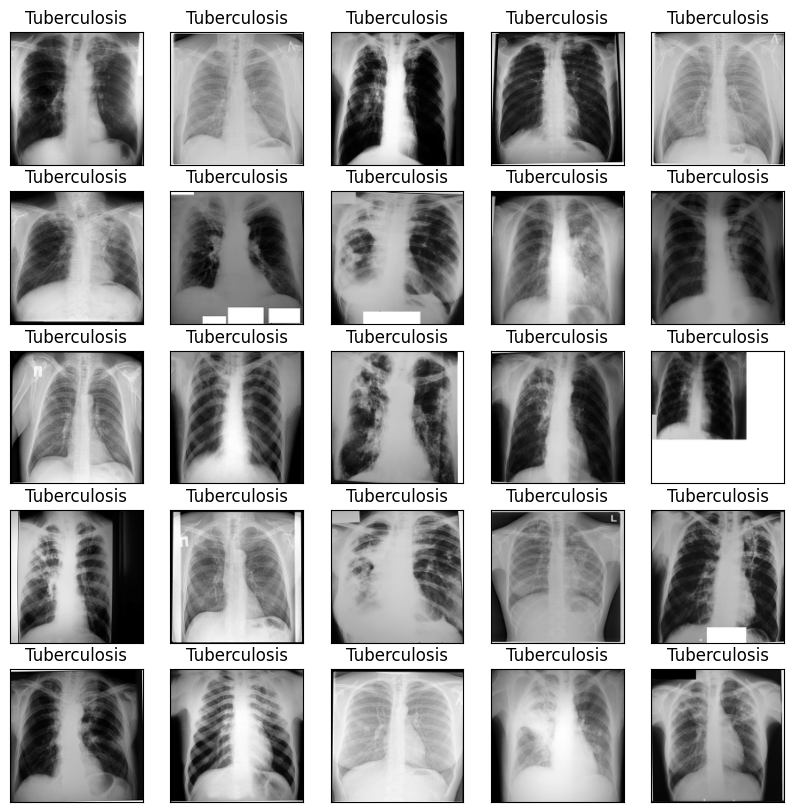

In [15]:
# Visualiser les 25 premières images des données
labels_str = ['Normal', 'Tuberculosis']
plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(data_images[data_images.shape[0]-i-1], cmap = 'gray')
  plt.title(labels_str[data_labels[data_images.shape[0]-i-1]])

In [16]:
# Nombre d'images  dans chaque classe
pd.Series(data_labels).value_counts()

,count
0,3500
1,700


<Axes: >

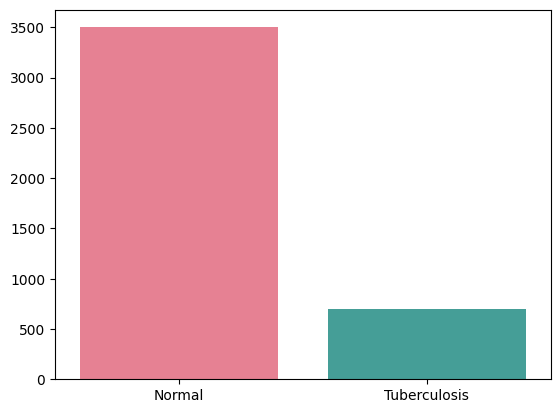

In [17]:
# Barplot du nombre d'images dans chaque classe
labels = ['Normal', 'Tuberculosis']
labels_numb = pd.Series(data_labels).value_counts().values
sns.barplot(x = labels, y =labels_numb, hue =labels,  palette= sns.husl_palette(2))

In [18]:
# spliter les données
from sklearn.model_selection import train_test_split
train_images,test_images, train_labels,test_labels = train_test_split(data_images, data_labels, test_size= 0.2, random_state=42)

In [19]:
# Normaliser
train_images,test_images = train_images/255, test_images/255

In [20]:
# Ajouter la dimension des canaux : (N, 150, 150) -> (N, 150, 150, 1)
train_images = np.expand_dims(train_images, axis=-1)
test_images = np.expand_dims(test_images, axis=-1)

In [21]:
# Répéter le canal gris 3 fois : (N, 150, 150, 1) -> (N, 150, 150, 3)
train_images = np.repeat(train_images, 3, axis=-1)
test_images = np.repeat(test_images, 3, axis=-1)

### Modèle de base

In [22]:
# Architecture du modèle
model = Sequential() # initialiser l'architecture CNN
# Couche convolutive 1 avec 16 filters
model.add(Conv2D(16, (3, 3), activation='relu', padding  = 'same', input_shape=(150,150,3)))
# Couche pooling 1
model.add(MaxPool2D((2, 2)))
# Couche convolutive 2 avec 16 filters
model.add(Conv2D(16, (3, 3), activation='relu', padding  = 'same'))
# couche pooling 2
model.add(MaxPool2D((2, 2)))
# couche convolutive 3 avec 16 filters
model.add(Conv2D(16, (3, 3), activation='relu', padding  = 'same'))
# couche pooling 3
model.add(MaxPool2D((2, 2)))
# couche convolutive 4 avec 32 filters
model.add(Conv2D(32, (3, 3), activation='relu', padding  = 'same'))
# couche pooling 4
model.add(MaxPool2D((2, 2)))
# couches fully connected
model.add(Flatten()) # couche flatten
model.add(Dense(units = 64, activation = 'relu', input_dim = 150)) # Dense 1
model.add(Dense(units = 32, activation = 'relu')) # Dense 2
model.add(Dense(units = 16 , activation = 'relu')) # Dense 3
model.add(Dense(units = 1, activation = 'sigmoid'))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2592)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       165,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,305 (696.50 KB)

 Trainable params: 178,305 (696.50 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
from keras.callbacks import EarlyStopping
# Compiler le modèle
model.compile(optimizer = 'adam', loss='binary_crossentropy', metrics=['accuracy', 'precision', 'recall'])
# Définir le early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3)
# Entrainer le modèle
history = model.fit(train_images, train_labels, validation_data=(test_images, test_labels), epochs=20, batch_size=32, callbacks= early_stopping)


Epoch 1/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 20s 82ms/step - accuracy: 0.8473 - loss: 0.3684 - precision: 0.6453 - recall: 0.1972 - val_accuracy: 0.9119 - val_loss: 0.2427 - val_precision: 0.8539 - val_recall: 0.5547
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9387 - loss: 0.1531 - precision: 0.8535 - recall: 0.7655 - val_accuracy: 0.9560 - val_loss: 0.1102 - val_precision: 0.9032 - val_recall: 0.8175
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9607 - loss: 0.1057 - precision: 0.9013 - recall: 0.8597 - val_accuracy: 0.9679 - val_loss: 0.0917 - val_precision: 0.9508 - val_recall: 0.8467
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9685 - loss: 0.0829 - precision: 0.9147 - recall: 0.8952 - val_accuracy: 0.9690 - val_loss: 0.0877 - val_precision: 0.9111 - val_recall: 0.8978
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9768 - loss: 0.0587 - precision: 0.9323 - recall: 0.9290 - val_accuracy: 0.9810 - val_lo

### Evaluation

In [24]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# y_pred:  prédictions du modèle sur les données validation
def CM_visualisation(model_objet):
    # Prédictions des deux modèles : probabilité > 0.5 => Tuberculosis (1), sinon Normal (0)
    test_pred = (model_objet.predict(test_images) > 0.5).astype(int).ravel()
    # Confusion matrix
    cnf_matr = confusion_matrix(test_labels,test_pred, labels=[0,1])

    # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                  display_labels=['Normal','Tuberculosis'])
    disp.plot() # Afficher la matrice de confusion
    plt.title('Matrice de confusion') # Définir le titre
    plt.show() # Afficher la figure

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step


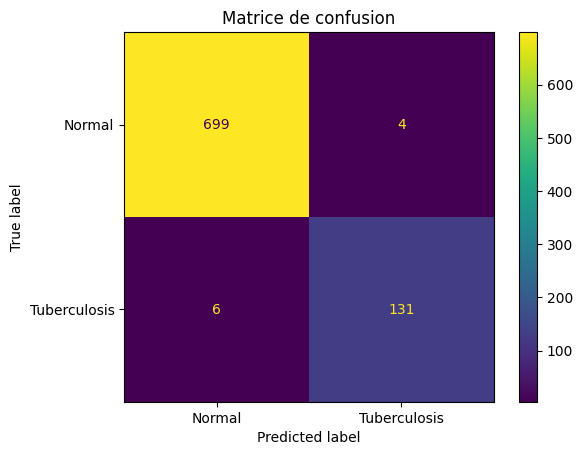

In [25]:
# matrice de confusion
CM_visualisation(model)

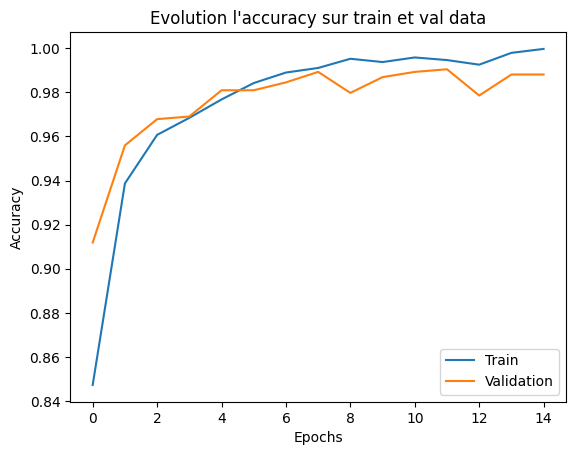

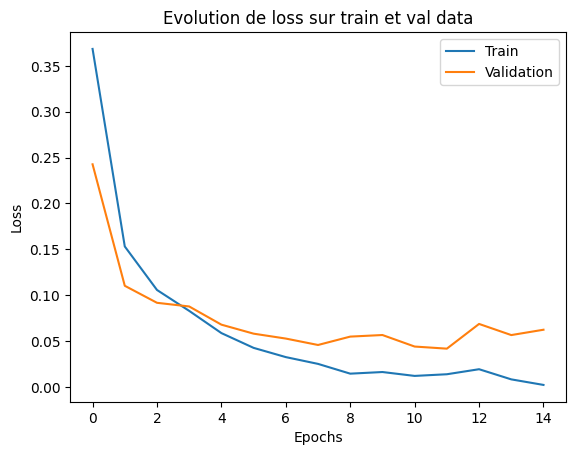

In [26]:
# Afficher l'évolution de l'accuracy sur les données d'entrainement et sur les données suivant les différents epochs
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Evolution l'accuracy sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc = 'lower right')
plt.show()
# Afficher l'évolution du loss sur les données d'entrainement et sur les données suivant les différents epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Evolution de loss sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc = 'upper right')
plt.show()

In [27]:
from sklearn import base
# Accuracy,loss,precision et recall sur validation data
base_model_metrics = model.evaluate(test_images, test_labels)
print(f'Loss : {base_model_metrics[0]} --- Accuracy : {base_model_metrics[1]} --- Precision: {base_model_metrics[2]} ...')

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9881 - loss: 0.0623 - precision: 0.9704 - recall: 0.9562
Loss : 0.06233454495668411 --- Accuracy : 0.988095223903656 --- Precision: 0.970370352268219 ...


In [28]:
# Accuracy,loss,precision et recall sur validation data
base_model_metrics_train = model.evaluate(test_images, test_labels)
print(f'Loss : {base_model_metrics_train[0]} --- Accuracy : {base_model_metrics_train[1]} --- Precision: {base_model_metrics_train[2]} ...')

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9881 - loss: 0.0623 - precision: 0.9704 - recall: 0.9562
Loss : 0.06233454495668411 --- Accuracy : 0.988095223903656 --- Precision: 0.970370352268219 ...


# Optimisation model de base

In [29]:

# Fonction build_model
def build_model(hp):
    model = Sequential()  # Initialiser l'architecture

    # Choisir le nombre de filtres optimal
    hp_filters1 = hp.Choice('filters1', values=[16, 32, 64, 128])
    hp_filters2 = hp.Choice('filters2', values=[16, 32, 64, 128])
    hp_filters3 = hp.Choice('filters3', values=[16, 32, 64, 128])
    hp_filters4 = hp.Choice('filters4', values=[16, 32, 64, 128])

    # Couches convolutives
    model.add(Conv2D(hp_filters1, (3, 3), activation='relu',
                     padding='same', input_shape=(150, 150, 3)))
    model.add(MaxPool2D((2, 2)))

    model.add(Conv2D(hp_filters2, (3, 3), activation='relu',
                     padding='same'))
    model.add(MaxPool2D((2, 2)))

    model.add(Conv2D(hp_filters3, (6, 6), activation='relu',
                     padding='same'))
    model.add(MaxPool2D((2, 2)))

    model.add(Conv2D(hp_filters4, (6, 6), activation='relu',
                     padding='same'))
    model.add(MaxPool2D((2, 2)))

    # Couches fully connected
    model.add(Flatten())
    model.add(Dense(units=64, activation='relu'))
    model.add(Dense(units=32, activation='relu'))
    model.add(Dense(units=16, activation='relu'))
    model.add(Dense(units=1, activation='sigmoid'))

    # Compiler le modèle
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model


In [30]:
%pip install -q keras-tuner

In [31]:

import keras_tuner as kt
from keras.callbacks import EarlyStopping

# Définir le Early Stopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3
)

# Initialiser le tuner Hyperband
tuner = kt.Hyperband(
    build_model,
    objective='accuracy',
    max_epochs=10,
    directory='tuner_dir'
)

# Lancer la recherche des meilleurs hyperparamètres
tuner.search(
    train_images,
    train_labels,
    validation_data=(test_images, test_labels),
    epochs=10,
    callbacks=[early_stopping]
)

# Afficher les meilleurs hyperparamètres
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

for i in range(1, 5):
    print(f"filters{i} :", best_hp.get(f"filters{i}"))

print("Nombre d'époques :", best_hp.get("tuner/epochs"))


Reloading Tuner from tuner_dir/untitled_project/tuner0.json
filters1 : 16
filters2 : 64
filters3 : 32
filters4 : 16
Nombre d'époques : 10


In [32]:
# Architecture du modèle CNN avec les filtres trouvés par Hyperband
model_optimise = Sequential()

# Définir la forme des images en entrée
model_optimise.add(Input(shape=(150, 150, 3)))

# Couche convolutive 1 : 32 filtres
model_optimise.add(Conv2D(16, (3, 3), activation='relu', padding='same'))
model_optimise.add(MaxPool2D((2, 2)))

# Couche convolutive 2 : 64 filtres
model_optimise.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
model_optimise.add(MaxPool2D((2, 2)))

# Couche convolutive 3 : 32 filtres
model_optimise.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
model_optimise.add(MaxPool2D((2, 2)))

# Couche convolutive 4 : 64 filtres
model_optimise.add(Conv2D(16, (3, 3), activation='relu', padding='same'))
model_optimise.add(MaxPool2D((2, 2)))

# Couches fully connected
model_optimise.add(Flatten())
model_optimise.add(Dense(units=64, activation='relu'))
model_optimise.add(Dense(units=32, activation='relu'))
model_optimise.add(Dense(units=16, activation='relu'))

# Couche de sortie : classification binaire
model_optimise.add(Dense(units=1, activation='sigmoid'))

# Compiler le modèle
model_optimise.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', 'precision', 'recall']
)

# Afficher l'architecture
model_optimise.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 150, 150, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 75, 75, 64)     │         9,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 37, 37, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 18, 18, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 18, 18, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 9, 9, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1296)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        83,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,449 (462.69 KB)

 Trainable params: 118,449 (462.69 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
# Compiler le modèle optimisé
model_optimise.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', 'precision', 'recall']
)






# Définir le Early Stopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3
)

# Entraîner le modèle optimisé
history_optimise = model_optimise.fit(
    train_images,
    train_labels,
    validation_data=(test_images, test_labels),
    epochs=10,
    batch_size=32,
    callbacks=[early_stopping]
)

Epoch 1/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 27s 136ms/step - accuracy: 0.8765 - loss: 0.2876 - precision: 0.7342 - recall: 0.4121 - val_accuracy: 0.9083 - val_loss: 0.2284 - val_precision: 0.8488 - val_recall: 0.5328
Epoch 2/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9193 - loss: 0.1920 - precision: 0.7920 - recall: 0.7034 - val_accuracy: 0.9357 - val_loss: 0.1665 - val_precision: 0.9109 - val_recall: 0.6715
Epoch 3/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9491 - loss: 0.1275 - precision: 0.8904 - recall: 0.7940 - val_accuracy: 0.9429 - val_loss: 0.1646 - val_precision: 0.9406 - val_recall: 0.6934
Epoch 4/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9670 - loss: 0.0884 - precision: 0.9139 - recall: 0.8863 - val_accuracy: 0.9690 - val_loss: 0.1023 - val_precision: 0.9440 - val_recall: 0.8613
Epoch 5/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9747 - loss: 0.0717 - precision: 0.9314 - recall: 0.9165 - val_accuracy: 0.9595 - val_l

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step


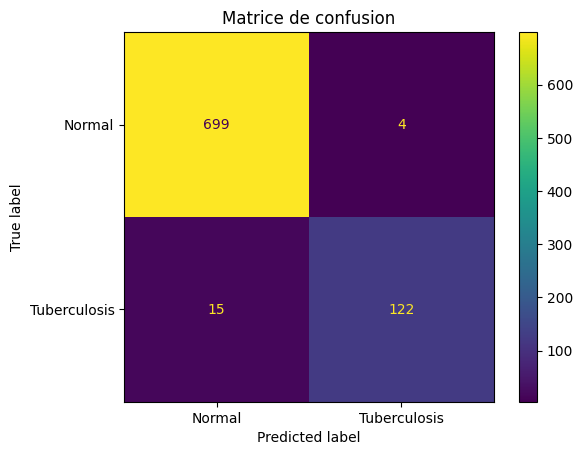

In [34]:
CM_visualisation(model_optimise)

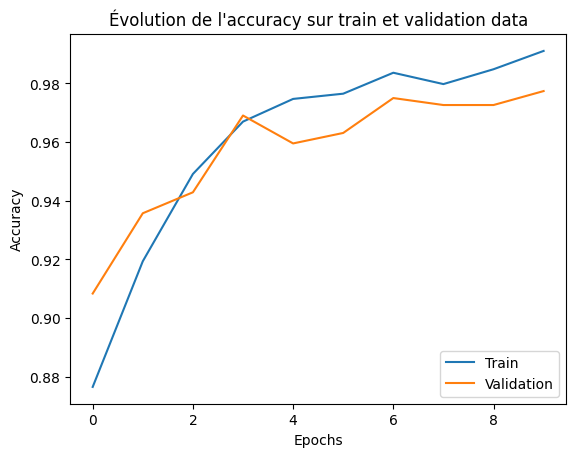

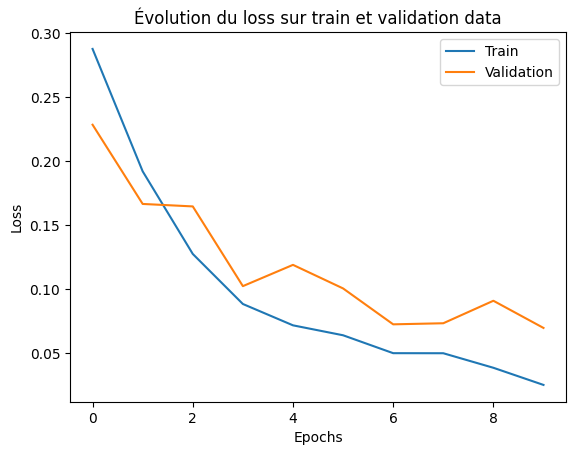

In [35]:
import matplotlib.pyplot as plt

# Afficher l'évolution de l'accuracy du CNN optimisé
plt.plot(history_optimise.history['accuracy'])
plt.plot(history_optimise.history['val_accuracy'])
plt.title("Évolution de l'accuracy sur train et validation data")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

# Afficher l'évolution du loss du CNN optimisé
plt.plot(history_optimise.history['loss'])
plt.plot(history_optimise.history['val_loss'])
plt.title("Évolution du loss sur train et validation data")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

In [36]:
# Accuracy, loss, precision et recall sur validation data
base_model_metrics_optimise = model_optimise.evaluate(test_images, test_labels)

print(f'Loss : {base_model_metrics_optimise[0]} --- Accuracy : {base_model_metrics_optimise[1]} --- Precision : {base_model_metrics_optimise[2]} ...')

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9774 - loss: 0.0697 - precision: 0.9683 - recall: 0.8905
Loss : 0.06969886273145676 --- Accuracy : 0.9773809313774109 --- Precision : 0.9682539701461792 ...


In [37]:
# Accuracy, loss, precision et recall sur train data
base_model_metrics_train_optimise = model_optimise.evaluate(train_images, train_labels)

print(f'Loss : {base_model_metrics_train_optimise[0]} --- Accuracy : {base_model_metrics_train_optimise[1]} --- Precision : {base_model_metrics_train_optimise[2]} ...')

105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9955 - loss: 0.0136 - precision: 0.9964 - recall: 0.9769
Loss : 0.013602998107671738 --- Accuracy : 0.9955357313156128 --- Precision : 0.9963768124580383 ...


### Modèle VGG16

In [38]:
# Charger VGG16 préentrainé sans les couches de classification (Sans couches fully connected)
base_vgg16 = VGG16(
    weights='imagenet',
    include_top=False,    #
    input_shape=(150, 150, 3)
)

# Geler les couches de base (Leurs poids, appris sur ImageNet, restent fixes pendant l’entraînement)
base_vgg16.trainable = False
# Construire le modèle VGG16 avec Sequential
vgg16_model = Sequential()
# Ajouter le modèle de base VGG16
vgg16_model.add(base_vgg16) # ajouter les couches de convolutions du modèle vgg16
# Applanir
vgg16_model.add(Flatten())
#couche fully connected -------------------------------------
# Couche Dense 1 avec 512 neurones
vgg16_model.add(Dense(units=512, activation='relu'))
# Couche Dropout 1
vgg16_model.add(Dropout(0.5))
# Couche Dense 2 avec 256 neurones
vgg16_model.add(Dense(units=256, activation='relu'))
# Couche Dropout 2
vgg16_model.add(Dropout(0.3))
# Couche de sortie pour classification binaire
vgg16_model.add(Dense(units=1, activation='sigmoid'))

In [39]:
# summary
vgg16_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 512)            │     4,194,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,041,089 (72.64 MB)

 Trainable params: 4,326,401 (16.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [40]:
# Compiler VGG16 customisé
vgg16_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', 'precision', 'recall']
)
# Entraînement VGG16
history_vgg16 = vgg16_model.fit(train_images, train_labels, validation_data=(test_images, test_labels), epochs=20, batch_size=32 ,callbacks= early_stopping) #, callbacks= early_stopping

Epoch 1/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 36s 189ms/step - accuracy: 0.9039 - loss: 0.2616 - precision: 0.7459 - recall: 0.6465 - val_accuracy: 0.9798 - val_loss: 0.0751 - val_precision: 0.9688 - val_recall: 0.9051
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - accuracy: 0.9711 - loss: 0.0760 - precision: 0.9299 - recall: 0.8952 - val_accuracy: 0.9690 - val_loss: 0.0805 - val_precision: 0.8535 - val_recall: 0.9781
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 11s 103ms/step - accuracy: 0.9765 - loss: 0.0704 - precision: 0.9481 - recall: 0.9094 - val_accuracy: 0.9893 - val_loss: 0.0416 - val_precision: 0.9923 - val_recall: 0.9416
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 20s 96ms/step - accuracy: 0.9845 - loss: 0.0469 - precision: 0.9637 - recall: 0.9432 - val_accuracy: 0.9881 - val_loss: 0.0467 - val_precision: 0.9922 - val_recall: 0.9343
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 11s 102ms/step - accuracy: 0.9833 - loss: 0.0438 - precision: 0.9617 - recall: 0.9378 - val_accuracy: 0.9881 

#### Evaluation

27/27 ━━━━━━━━━━━━━━━━━━━━ 4s 118ms/step


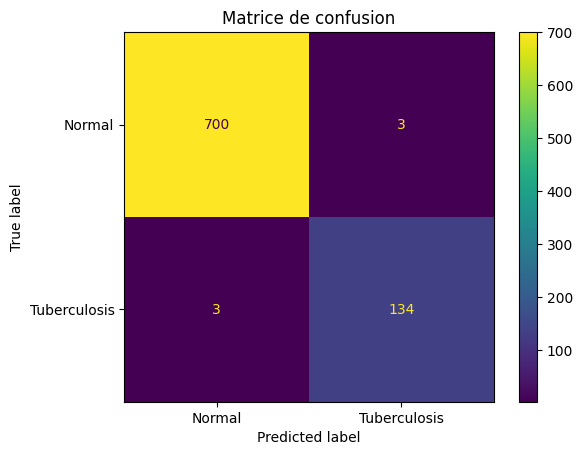

In [41]:
# matrice de confusion
CM_visualisation(vgg16_model)


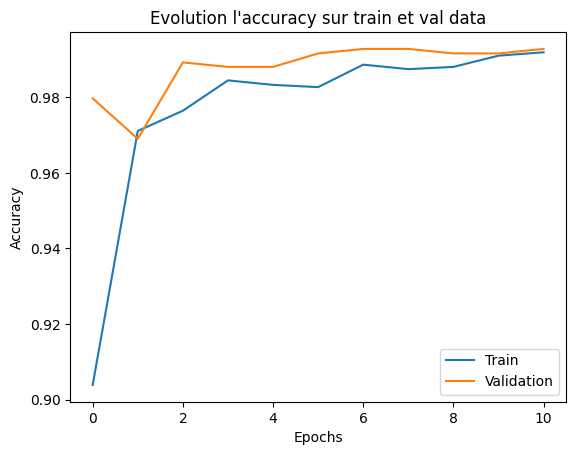

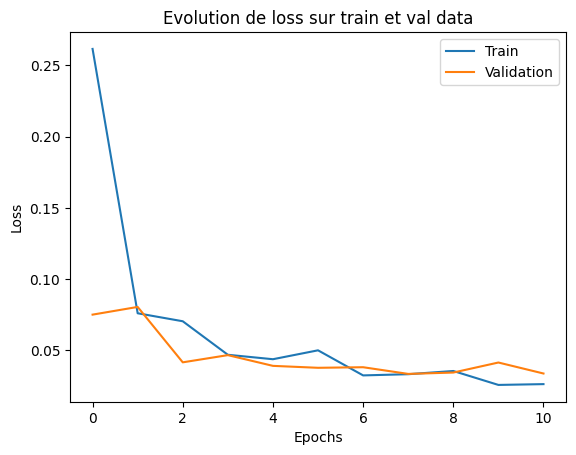

In [42]:
# Afficher l'évolution de l'accuracy sur les données d'entrainement et sur les données validation suivant les différents epochs
plt.plot(history_vgg16.history['accuracy'])
plt.plot(history_vgg16.history['val_accuracy'])
plt.title("Evolution l'accuracy sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc = 'lower right')
plt.show()
# Afficher l'évolution du loss sur les données d'entrainement et sur les données validation suivant les différents epochs
plt.plot(history_vgg16.history['loss'])
plt.plot(history_vgg16.history['val_loss'])
plt.title("Evolution de loss sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc = 'upper right')
plt.show()

In [43]:
# Accuracy,loss,precision et recall sur validation data

base_model_metrics = model.evaluate(test_images, test_labels)
print(f'Loss : {base_model_metrics[0]} --- Accuracy : {base_model_metrics[1]} --- Precision : {base_model_metrics[2]} --- Recall : {base_model_metrics[3]}')



27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9881 - loss: 0.0623 - precision: 0.9704 - recall: 0.9562
Loss : 0.06233454495668411 --- Accuracy : 0.988095223903656 --- Precision : 0.970370352268219 --- Recall : 0.956204354763031


In [44]:
# Accuracy et loss sur les données train data
base_model_train_metrics = model.evaluate(train_images, train_labels)
print(f'Loss : {base_model_train_metrics[0]} --- Accuracy : {base_model_train_metrics[1]}')

105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 1.0000 - loss: 6.2680e-04 - precision: 1.0000 - recall: 1.0000
Loss : 0.0006267954013310373 --- Accuracy : 1.0


# la recherche des hyperparamètres du modèle VGG16

In [45]:
def build_model_vgg16(hp):
    base_vgg16 = VGG16(
        weights="imagenet",
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_vgg16.trainable = False

    model_vgg16 = Sequential()
    model_vgg16.add(base_vgg16)
    model_vgg16.add(Flatten())

    units1_vgg16 = hp.Choice(
        "units1_vgg16",
        values=[256, 512, 1024]
    )
    model_vgg16.add(Dense(units=units1_vgg16, activation="relu"))

    dropout1_vgg16 = hp.Choice(
        "dropout1_vgg16",
        values=[0.3, 0.5]
    )
    model_vgg16.add(Dropout(dropout1_vgg16))

    units2_vgg16 = hp.Choice(
        "units2_vgg16",
        values=[128, 256, 512]
    )
    model_vgg16.add(Dense(units=units2_vgg16, activation="relu"))

    dropout2_vgg16 = hp.Choice(
        "dropout2_vgg16",
        values=[0.2, 0.3, 0.5]
    )
    model_vgg16.add(Dropout(dropout2_vgg16))

    model_vgg16.add(Dense(1, activation="sigmoid"))

    model_vgg16.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model_vgg16

In [46]:

# Initialiser Hyperband
tuner_vgg16 = kt.Hyperband(
    build_model_vgg16,
    objective='accuracy',
    max_epochs=10,
    directory='tuner_dir',
    project_name='vgg16'
)

# Définir EarlyStopping
early_stopping_vgg16 = EarlyStopping(
    monitor='val_loss',
    patience=3
)

# Lancer la recherche
tuner_vgg16.search(
    train_images,
    train_labels,
    validation_data=(test_images, test_labels),
    epochs=10,
    batch_size=32,
    callbacks=[early_stopping_vgg16]
)


Reloading Tuner from tuner_dir/vgg16/tuner0.json


In [47]:
# Afficher les paramètres optimaux de VGG16
for h_param in [
    'units1_vgg16',
    'dropout1_vgg16',
    'units2_vgg16',
    'dropout2_vgg16',
    'tuner/epochs'
]:
    print(
        h_param,
        tuner_vgg16.get_best_hyperparameters()[0].get(h_param)
    )

units1_vgg16 1024
dropout1_vgg16 0.3
units2_vgg16 512
dropout2_vgg16 0.3
tuner/epochs 10


In [48]:
# Architecture du modèle final VGG16
model_vgg16 = Sequential(name='model_vgg16')

# Réutiliser la base VGG16 déjà chargée
model_vgg16.add(base_vgg16)

# Couche Flatten
model_vgg16.add(Flatten())

# Couches Dense avec les paramètres trouvés par Hyperband
model_vgg16.add(Dense(units=1024, activation='relu'))
model_vgg16.add(Dropout(0.3))

model_vgg16.add(Dense(units=512, activation='relu'))
model_vgg16.add(Dropout(0.3))

# Classification binaire
model_vgg16.add(Dense(units=1, activation='sigmoid'))

# Afficher l'architecture
model_vgg16.summary()

Model: "model_vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1024)           │     8,389,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,629,633 (90.14 MB)

 Trainable params: 8,914,945 (34.01 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [49]:
from keras.callbacks import EarlyStopping

# Compiler le modèle VGG16
model_vgg16.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', 'precision', 'recall']
)



# Définir le callback EarlyStopping
early_stopping_vgg16 = EarlyStopping(
    monitor='val_loss',
    patience=3
)

# Entraîner le modèle VGG16
history_vgg16 = model_vgg16.fit(
    train_images,
    train_labels,
    validation_data=(test_images, test_labels),
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping_vgg16]
)

Epoch 1/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 19s 133ms/step - accuracy: 0.9214 - loss: 0.2244 - precision: 0.7848 - recall: 0.7318 - val_accuracy: 0.9821 - val_loss: 0.0615 - val_precision: 0.9841 - val_recall: 0.9051
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - accuracy: 0.9795 - loss: 0.0658 - precision: 0.9507 - recall: 0.9254 - val_accuracy: 0.9810 - val_loss: 0.0637 - val_precision: 0.9919 - val_recall: 0.8905
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 12s 111ms/step - accuracy: 0.9878 - loss: 0.0394 - precision: 0.9677 - recall: 0.9591 - val_accuracy: 0.9821 - val_loss: 0.0545 - val_precision: 1.0000 - val_recall: 0.8905
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 11s 104ms/step - accuracy: 0.9836 - loss: 0.0548 - precision: 0.9585 - recall: 0.9432 - val_accuracy: 0.9786 - val_loss: 0.0837 - val_precision: 1.0000 - val_recall: 0.8686
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 11s 101ms/step - accuracy: 0.9875 - loss: 0.0325 - precision: 0.9711 - recall: 0.9538 - val_accuracy: 0.9917

27/27 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step


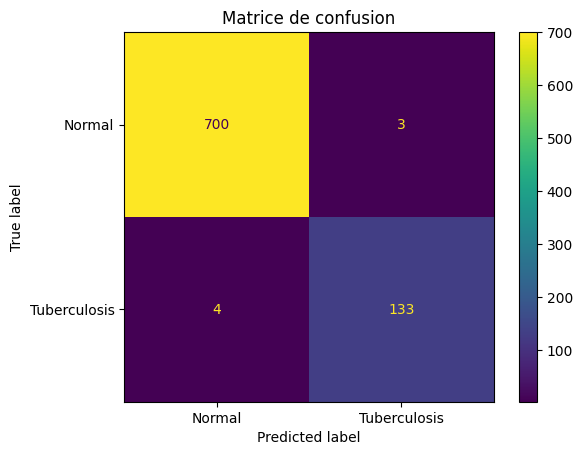

In [50]:
# matrice de confusion
CM_visualisation(model_vgg16)

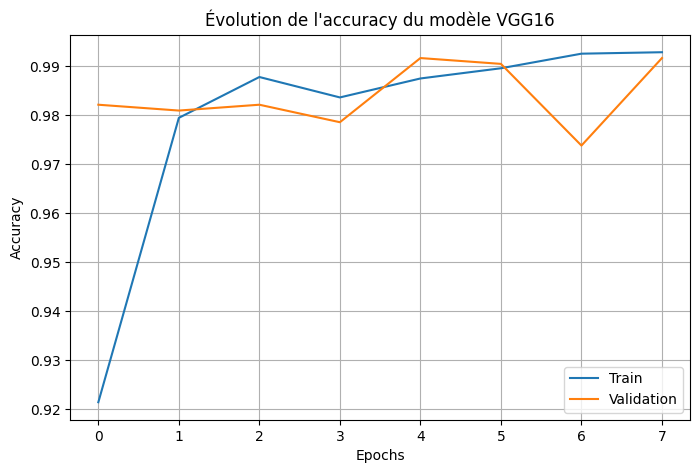

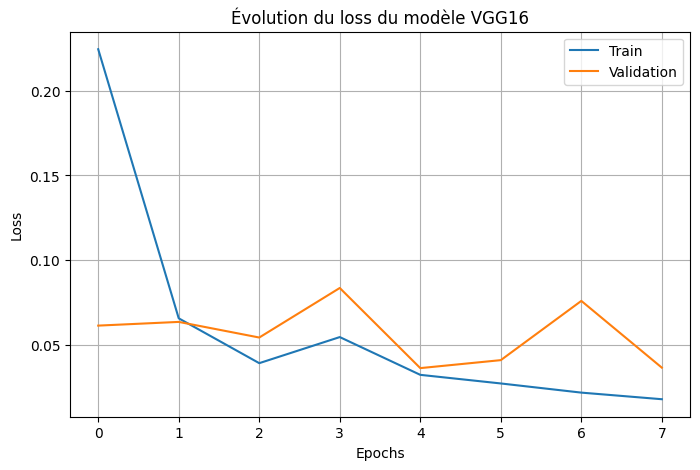

In [51]:
plt.figure(figsize=(8, 5))
plt.plot(history_vgg16.history['accuracy'])
plt.plot(history_vgg16.history['val_accuracy'])
plt.title("Évolution de l'accuracy du modèle VGG16")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.grid(True)
plt.show()


# Afficher l'évolution du loss sur les données d'entraînement et de validation
plt.figure(figsize=(8, 5))
plt.plot(history_vgg16.history['loss'])
plt.plot(history_vgg16.history['val_loss'])
plt.title("Évolution du loss du modèle VGG16")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.grid(True)
plt.show()

In [52]:
# Accuracy, precision et recall sur validation data

base_model_metrics_vgg16 = model_vgg16.evaluate(test_images, test_labels)
print(f'Loss : {base_model_metrics_vgg16[0]} --- Accuracy : {base_model_metrics_vgg16[1]} --- Precision : {base_model_metrics_vgg16[2]} --- Recall : {base_model_metrics_vgg16[3]}')

27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - accuracy: 0.9917 - loss: 0.0368 - precision: 0.9779 - recall: 0.9708
Loss : 0.03676186874508858 --- Accuracy : 0.9916666746139526 --- Precision : 0.9779411554336548 --- Recall : 0.970802903175354


In [53]:


# Accuracy, precision et recall sur train data

base_model_metrics_vgg16 = model_vgg16.evaluate(train_images, train_labels)
print(f'Loss : {base_model_metrics_vgg16[0]} --- Accuracy : {base_model_metrics_vgg16[1]} --- Precision : {base_model_metrics_vgg16[2]} --- Recall : {base_model_metrics_vgg16[3]}')

105/105 ━━━━━━━━━━━━━━━━━━━━ 9s 84ms/step - accuracy: 0.9994 - loss: 0.0026 - precision: 0.9965 - recall: 1.0000
Loss : 0.0025673964992165565 --- Accuracy : 0.999404788017273 --- Precision : 0.9964601993560791 --- Recall : 1.0


### Modèle DenseNet121

In [54]:
# Importer DenseNet121
from tensorflow.keras.applications import DenseNet121

In [55]:
# Charger DenseNet121 préentrainé sans les couches de classification (Sans couches fully connected)
base_densenet = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(150, 150, 3)
)

# Geler les couches de base
base_densenet.trainable = False
# Construire le modèle DenseNet121 avec Sequential
densenet_model = Sequential()
# Ajouter le modèle de base DenseNet121
densenet_model.add(base_densenet) # ajouter les couches de convolutions du modèle DenseNet121
# Applanir
densenet_model.add(Flatten())
# Couche Dense 1 avec 512 neurones
densenet_model.add(Dense(units=512, activation='relu'))
# Couche Dropout 1
densenet_model.add(Dropout(0.5))
# Couche Dense 2 avec 256 neurones
densenet_model.add(Dense(units=256, activation='relu'))
# Couche Dropout 2
densenet_model.add(Dropout(0.3))
# Couche de sortie pour classification binaire
densenet_model.add(Dense(units=1, activation='sigmoid'))

In [56]:
# Compiler DenseNet121 customisé
densenet_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', 'precision', 'recall']
)
# Entraînement DenseNet121

history_densenet_model = densenet_model.fit(train_images, train_labels, validation_data=(test_images, test_labels), epochs=20, batch_size=32 ,callbacks= early_stopping)


Epoch 1/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 144s 720ms/step - accuracy: 0.9098 - loss: 0.8431 - precision: 0.7416 - recall: 0.7087 - val_accuracy: 0.9536 - val_loss: 0.2213 - val_precision: 0.9712 - val_recall: 0.7372
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 18s 60ms/step - accuracy: 0.9586 - loss: 0.1543 - precision: 0.8911 - recall: 0.8579 - val_accuracy: 0.9631 - val_loss: 0.1102 - val_precision: 0.8272 - val_recall: 0.9781
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.9688 - loss: 0.0900 - precision: 0.9164 - recall: 0.8952 - val_accuracy: 0.9738 - val_loss: 0.0619 - val_precision: 0.9457 - val_recall: 0.8905


#### Evaluation

27/27 ━━━━━━━━━━━━━━━━━━━━ 28s 576ms/step


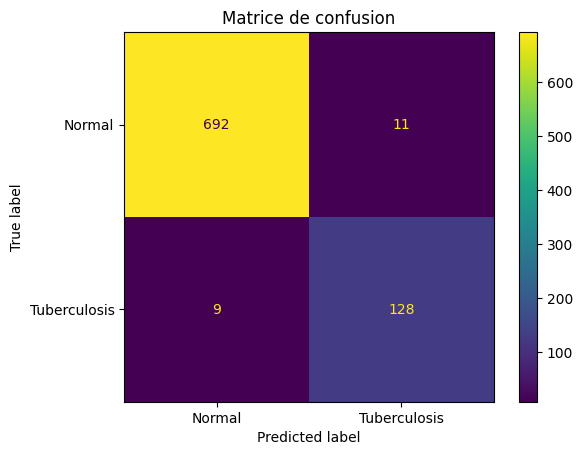

In [56]:
# Matrice de confusion
CM_visualisation(densenet_model)

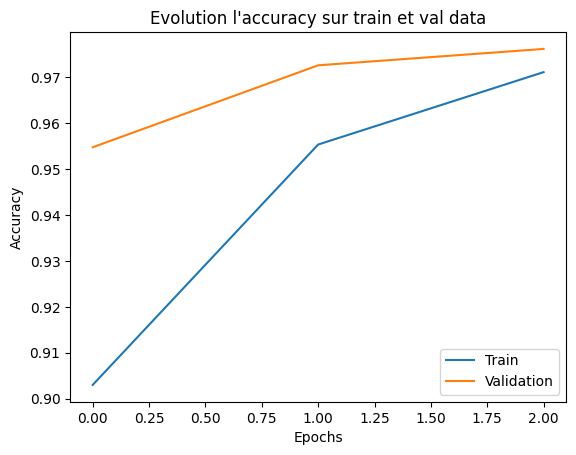

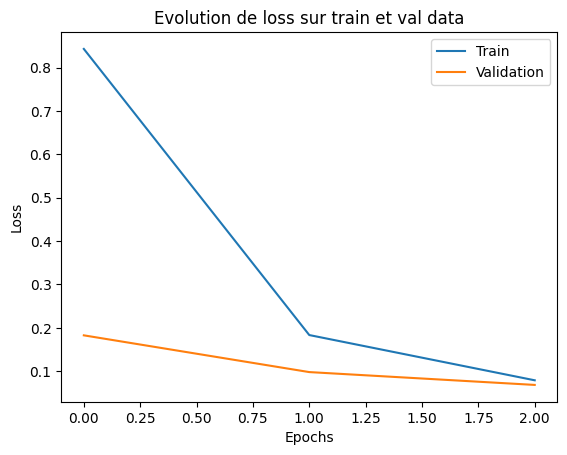

In [57]:
# Afficher l'évolution de l'accuracy sur les données d'entrainement et sur les données validation suivant les différents epochs
plt.plot(history_densenet_model.history['accuracy'])
plt.plot(history_densenet_model.history['val_accuracy'])
plt.title("Evolution l'accuracy sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc = 'lower right')
plt.show()
# Afficher l'évolution du loss sur les données d'entrainement et sur les données validation suivant les différents epochs
plt.plot(history_densenet_model.history['loss'])
plt.plot(history_densenet_model.history['val_loss'])
plt.title("Evolution de loss sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc = 'upper right')
plt.show()

In [58]:
# Accuracy, loss, precision et recall sur validation data
densenet_model_metrics = densenet_model.evaluate(test_images, test_labels)
print(f'Loss : {densenet_model_metrics[0]} --- Accuracy : {densenet_model_metrics[1]} --- Precision: {densenet_model_metrics[2]} ...')


27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.9762 - loss: 0.0685 - precision: 0.9209 - recall: 0.9343
Loss : 0.06854549795389175 --- Accuracy : 0.976190447807312 --- Precision: 0.9208633303642273 ...


In [59]:
# Accuracy, loss, precision et recall sur les données train data


densenet_model_metrics = densenet_model.evaluate(train_images, train_labels)
print(f'Loss : {densenet_model_metrics[0]} --- Accuracy : {densenet_model_metrics[1]} --- Precision: {densenet_model_metrics[2]} ...')



105/105 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.9899 - loss: 0.0267 - precision: 0.9698 - recall: 0.9698
Loss : 0.026747452095150948 --- Accuracy : 0.9898809790611267 --- Precision: 0.9698046445846558 ...


# DenseNet121 optimise


In [58]:

def build_model_densenet(hp):

    base_densenet = DenseNet121(
        weights="imagenet",
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_densenet.trainable = False

    densenet_model_optimise = Sequential()
    densenet_model_optimise.add(base_densenet)
    densenet_model_optimise.add(Flatten())

    units1_densenet = hp.Choice(
        "units1_densenet",
        values=[256, 512, 1024]
    )
    densenet_model_optimise.add(
        Dense(units=units1_densenet, activation="relu")
    )

    dropout1_densenet = hp.Choice(
        "dropout1_densenet",
        values=[0.3, 0.5]
    )
    densenet_model_optimise.add(Dropout(dropout1_densenet))

    units2_densenet = hp.Choice(
        "units2_densenet",
        values=[128, 256, 512]
    )
    densenet_model_optimise.add(
        Dense(units=units2_densenet, activation="relu")
    )

    dropout2_densenet = hp.Choice(
        "dropout2_densenet",
        values=[0.2, 0.3, 0.5]
    )
    densenet_model_optimise.add(Dropout(dropout2_densenet))

    densenet_model_optimise.add(Dense(1, activation="sigmoid"))

    densenet_model_optimise.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return densenet_model_optimise


In [60]:

# Initialiser Hyperband
tuner_densenet = kt.Hyperband(
    build_model_densenet,
    objective='accuracy',
    max_epochs=10,
    directory='tuner_dir',
    project_name='densenet'
)

# Définir EarlyStopping
early_stopping_densenet = EarlyStopping(
    monitor='val_loss',
    patience=3
)

# Lancer la recherche
tuner_densenet.search(
    train_images,
    train_labels,
    validation_data=(test_images, test_labels),
    epochs=10,
    batch_size=32,
    callbacks=[early_stopping_densenet]
)


Reloading Tuner from tuner_dir/densenet/tuner0.json


In [61]:
# Récupérer les meilleurs hyperparamètres
best_hps_densenet = tuner_densenet.get_best_hyperparameters(num_trials=1)[0]

# Afficher les valeurs optimales
for h_param in [
    'units1_densenet',
    'dropout1_densenet',
    'units2_densenet',
    'dropout2_densenet'
]:
    print(h_param, best_hps_densenet.get(h_param))

units1_densenet 1024
dropout1_densenet 0.3
units2_densenet 512
dropout2_densenet 0.5


In [63]:

# Architecture du modèle final DenseNet121
densenet_model_optimise = Sequential(name='densenet_model')

# Réutiliser la base DenseNet121 déjà chargée et préentraînée sur ImageNet
densenet_model_optimise.add(base_densenet)

# Couche Flatten
densenet_model_optimise.add(Flatten())

# Couches Dense avec les paramètres trouvés par Hyperband
densenet_model_optimise.add(Dense(units=1024, activation='relu'))
densenet_model_optimise.add(Dropout(0.3))

densenet_model_optimise.add(Dense(units=512, activation='relu'))
densenet_model_optimise.add(Dropout(0.5))

# Classification binaire
densenet_model_optimise.add(Dense(units=1, activation='sigmoid'))

# Afficher l'architecture
densenet_model_optimise.summary()


Model: "densenet_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 4, 4, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1024)           │    16,778,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,341,057 (92.85 MB)

 Trainable params: 17,303,553 (66.01 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [64]:

from keras.callbacks import EarlyStopping

# Compiler le modèle DenseNet121
densenet_model_optimise.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', 'precision', 'recall']
)

# Définir le callback EarlyStopping
early_stopping_densenet = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Entraîner le modèle DenseNet121
history_densenet_model_optimise = densenet_model_optimise.fit(
    train_images,
    train_labels,
    validation_data=(test_images, test_labels),
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping_densenet]
)


Epoch 1/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 60s 309ms/step - accuracy: 0.8997 - loss: 1.0612 - precision: 0.7070 - recall: 0.6856 - val_accuracy: 0.9619 - val_loss: 0.1876 - val_precision: 0.8302 - val_recall: 0.9635
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.9658 - loss: 0.1735 - precision: 0.9000 - recall: 0.8952 - val_accuracy: 0.9750 - val_loss: 0.1050 - val_precision: 0.9754 - val_recall: 0.8686
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - accuracy: 0.9798 - loss: 0.0758 - precision: 0.9412 - recall: 0.9378 - val_accuracy: 0.9845 - val_loss: 0.0564 - val_precision: 0.9366 - val_recall: 0.9708
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - accuracy: 0.9827 - loss: 0.0668 - precision: 0.9501 - recall: 0.9467 - val_accuracy: 0.9786 - val_loss: 0.0621 - val_precision: 0.9343 - val_recall: 0.9343
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 7s 64ms/step - accuracy: 0.9863 - loss: 0.0434 - precision: 0.9658 - recall: 0.9520 - val_accuracy: 0.9774 - val_l

27/27 ━━━━━━━━━━━━━━━━━━━━ 29s 586ms/step


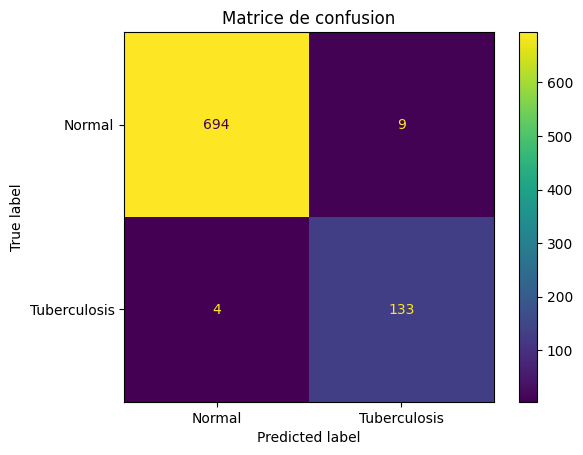

In [65]:
# Matrice de confusion
CM_visualisation(densenet_model_optimise)

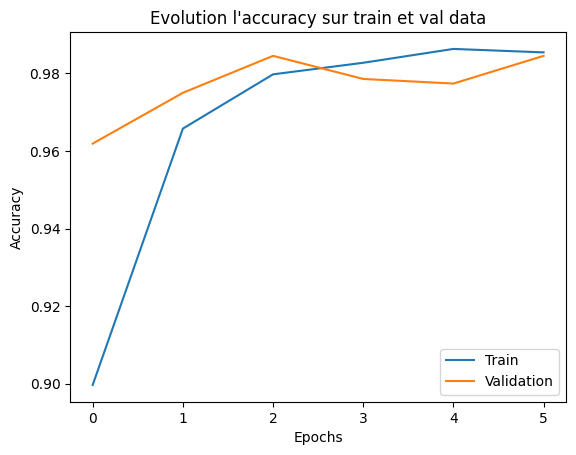

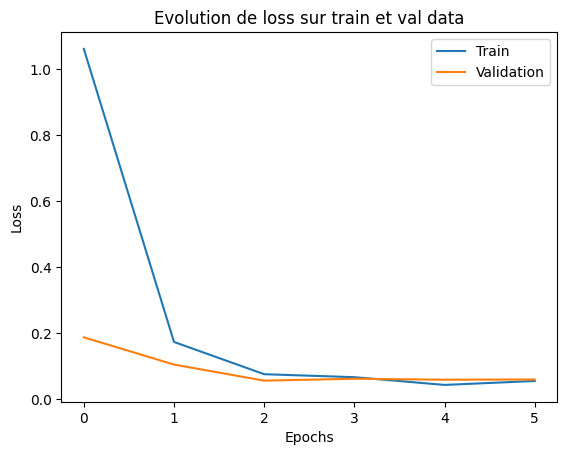

In [66]:
# Afficher l'évolution de l'accuracy sur les données d'entrainement et sur les données validation suivant les différents epochs
plt.plot(history_densenet_model_optimise.history['accuracy'])
plt.plot(history_densenet_model_optimise.history['val_accuracy'])
plt.title("Evolution l'accuracy sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc = 'lower right')
plt.show()
# Afficher l'évolution du loss sur les données d'entrainement et sur les données validation suivant les différents epochs
plt.plot(history_densenet_model_optimise.history['loss'])
plt.plot(history_densenet_model_optimise.history['val_loss'])
plt.title("Evolution de loss sur train et val data")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc = 'upper right')
plt.show()

In [67]:
# Accuracy, loss, precision et recall sur validation data
densenet_model_optimise_metrics = densenet_model_optimise.evaluate(test_images, test_labels)
print(f'Loss : {densenet_model_optimise_metrics[0]} --- Accuracy : {densenet_model_optimise_metrics[1]} --- Precision: {densenet_model_optimise_metrics[2]} ...')


27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.9845 - loss: 0.0564 - precision: 0.9366 - recall: 0.9708
Loss : 0.05635412409901619 --- Accuracy : 0.9845238327980042 --- Precision: 0.9366196990013123 ...


In [68]:
# Accuracy, loss, precision et recall sur les données train data


densenet_model_optimise_metrics = densenet_model_optimise.evaluate(train_images, train_labels)
print(f'Loss : {densenet_model_optimise_metrics[0]} --- Accuracy : {densenet_model_optimise_metrics[1]} --- Precision: {densenet_model_optimise_metrics[2]} ...')



105/105 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.9929 - loss: 0.0180 - precision: 0.9753 - recall: 0.9822
Loss : 0.017984746024012566 --- Accuracy : 0.9928571581840515 --- Precision: 0.9753086566925049 ...


In [69]:
import pandas as pd

def comparer_modeles(
    model,
    model_optimise,
    vgg16_model,
    model_vgg16,
    densenet_model,
    densenet_model_optimise,
    test_images,
    test_labels
):
    modeles = {
        "model": model,
        "model_optimise": model_optimise,
        "vgg16_model": vgg16_model,
        "model_vgg16": model_vgg16,
        "densenet_model": densenet_model,
        "densenet_model_optimise": densenet_model_optimise
    }

    resultats = []

    for nom, modele in modeles.items():
        valeurs = modele.evaluate(
            test_images,
            test_labels,
            verbose=0,
            return_dict=True
        )

        precision = float(valeurs["precision"])
        recall = float(valeurs["recall"])

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0
            else 0.0
        )

        resultats.append({
            "Modèle": nom,
            "Accuracy": float(valeurs["accuracy"]),
            "Precision": precision,
            "Recall": recall,
            "F1-score": f1,
            "Loss": float(valeurs["loss"])
        })

    tableau = pd.DataFrame(resultats).sort_values(
        "F1-score", ascending=False
    ).reset_index(drop=True)

    nom_meilleur = tableau.loc[0, "Modèle"]
    meilleur_modele = modeles[nom_meilleur]

    print("Meilleur modèle selon le F1-score :", nom_meilleur)
    display(tableau)

    return meilleur_modele

In [70]:
meilleur_modele = comparer_modeles(
    model,
    model_optimise,
    vgg16_model,
    model_vgg16,
    densenet_model,
    densenet_model_optimise,
    test_images,
    test_labels
)

Meilleur modèle selon le F1-score : vgg16_model


,Modèle,Accuracy,Precision,Recall,F1-score,Loss
0,vgg16_model,0.992857,0.978102,0.978102,0.978102,0.033760
1,model_vgg16,0.991667,0.977941,0.970803,0.974359,0.036762
2,model,0.988095,0.970370,0.956204,0.963235,0.062335
3,densenet_model_optimise,0.984524,0.936620,0.970803,0.953405,0.056354
4,densenet_model,0.982143,0.935714,0.956204,0.945848,0.050151
5,model_optimise,0.977381,0.968254,0.890511,0.927757,0.069699


### Télécharger le modèle le plus performant

In [72]:

# Télécharger le modèle
model.save('vgg16_model.h5')

### Prédictions

In [ ]:
# Fonction convertissant l'image à la dimension exacte utilisée sur le training
rom PIL import Image

def imageToArray(image_path):

  width, height = 150, 150  #Remplacer par les dimensions requises par notre modèle

  image = Image.open(image_path).convert('RGB')
  image = image.resize((width, height))
  # Convertir l'image en numpy arraay et normaliser les valeurs des pixels (si nécessaire)
  image_array = np.asarray(image)
  image_array = image_array / 255.0  # Normaliser les valeurs des pixels entre 0 et 1

  # Redimensionner la matrice image pour qu'elle correspond à la forme d'entrée de  notre modèle
  image_array = image_array.reshape(-1, width, height, 3)

  return image_array

In [ ]:
lass_names = ['Normal', 'Tuberculosis']
# Predictions
image_path = ''
image = imageToArray(image_path)
pred = int(np.round(vgg16_model.predict(image))[0][0])
pred = class_names[pred]
plt.imshow(Image.open(image_path)) # afficher l'image
plt.xlabel(f'Prédiction : {pred}')
plt.show()

### Deploiement du modèle en utilisant Gradio

In [ ]:
import tensorflow as tf
import numpy as np
import gradio as gr
from PIL import Image

# Charger le modèle entraîné
odel = tf.keras.models.load_model("vgg16_model_finetuned.h5")  # adapter le nom du fichier

# Paramètres issus de l'entraînement
IMG_SIZE = (150, 150)
CLASSES = ["Normal", "Tuberculosis"]

# Prétraitement + prédiction
def predict(image):
    if image is None:
        return None
    image = image.convert("RGB")                        # gris/RGBA -> 3 canaux
    image = image.resize(IMG_SIZE, Image.NEAREST)       # même interpolation que Keras
    image_array = np.asarray(image, dtype=np.float32) / 255.0  # même rescale
    image_array = np.expand_dims(image_array, axis=0)   # (1, 150, 150, 3)

    p_tb = float(model.predict(image_array, verbose=0)[0][0])
    return {CLASSES[1]: p_tb, CLASSES[0]: 1.0 - p_tb}

# Interface Gradio
interface = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="Radiographie thoracique"),
    outputs=gr.Label(num_top_classes=2, label="Résultat"),
    title="Détection de la tuberculose sur radiographie thoracique",
    description=(
        "Téléversez une radiographie thoracique pour estimer la probabilité de tuberculose. "
        "Outil pédagogique : il ne remplace pas un diagnostic médical."
    ),
    theme="JohnSmith9982/small_and_pretty",
)
interface.launch(share=True)